# **TV Advertising and Sales – Simple Linear Regression Analysis**

### _This analysis uses simple linear regression to examine the relationship between TV advertising expenditure and product sales. The goal is to determine whether advertising spending significantly predicts sales and evaluate the model's accuracy using statistical measures and regression diagnostics._

## Objectives

1. Explore and visualize the dataset.
2. Examine the relationship between TV advertising and sales.
3. Fit a simple linear regression model.
4. Evaluate statistical significance and model performance.
5. Check regression assumptions using diagnostic plots.
6. Interpret the results from a business perspective.

In [12]:
# Import necessary libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2

from lm_manual_class import lm_manual

## 1. Dataset Overview

The dataset contains advertising expenditure across different media channels and the corresponding product sales.

For this analysis, only two variables will be considered:

- **TV:** Advertising expenditure in thousands of dollars.
- **Sales:** Product sales in thousands of units.

TV advertising expenditure is the independent variable, while sales is the dependent variable.

In [10]:
# Load and inspect dataset

url = "https://raw.githubusercontent.com/RamakshaB/Sklearn-Datasets/main/Advertising.csv"
df = pd.read_csv(url)
df.head()
print("Dataset Shape:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum())
print("\nSummary Statistics:")
df[["TV", "sales"]].describe()

Dataset Shape: (200, 4)

Missing Values:
TV           0
radio        0
newspaper    0
sales        0
dtype: int64

Summary Statistics:


,TV,sales
count,200.000000,200.000000
mean,147.042500,14.022500
std,85.854236,5.217457
min,0.700000,1.600000
25%,74.375000,10.375000
50%,149.750000,12.900000
75%,218.825000,17.400000
max,296.400000,27.000000


## 2. Exploratory Data Analysis (EDA)

Before fitting a simple linear regression model, exploratory data analysis is conducted to examine the relationship between **TV advertising expenditure** and **product sales**, as well as the distributions of both variables.

The analysis uses a **scatterplot, Pearson correlation coefficient, and boxplots** to better understand the dataset.

The purpose of these visualizations is to:

- **Identify trends:** Determine whether higher TV advertising expenditure is associated with increased product sales.
- **Assess linearity:** Examine whether the relationship between advertising expenditure and sales follows an approximately linear pattern.
- **Measure correlation:** Calculate the Pearson correlation coefficient to evaluate the strength and direction of the linear relationship.
- **Detect outliers:** Use boxplots to identify unusually high or low values in either variable.
- **Examine variability:** Evaluate the spread and distribution of TV advertising expenditure and product sales.
- **Assess central tendency:** Use boxplots to examine the median and quartiles of each variable.

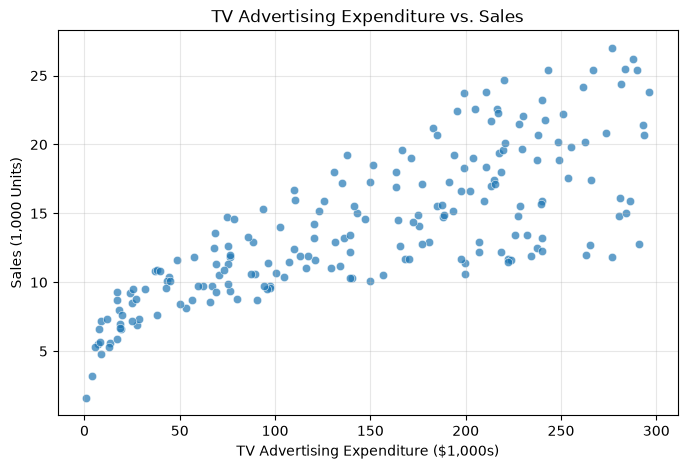

Pearson Correlation Coefficient: 0.7822


In [5]:
# Scatterplot 

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="TV", y="sales", alpha=0.7)
plt.title("TV Advertising Expenditure vs. Sales")
plt.xlabel("TV Advertising Expenditure ($1,000s)")
plt.ylabel("Sales (1,000 Units)")
plt.grid(alpha=0.3)
plt.show()
correlation = df["TV"].corr(df["sales"])
print(f"Pearson Correlation Coefficient: {correlation:.4f}")


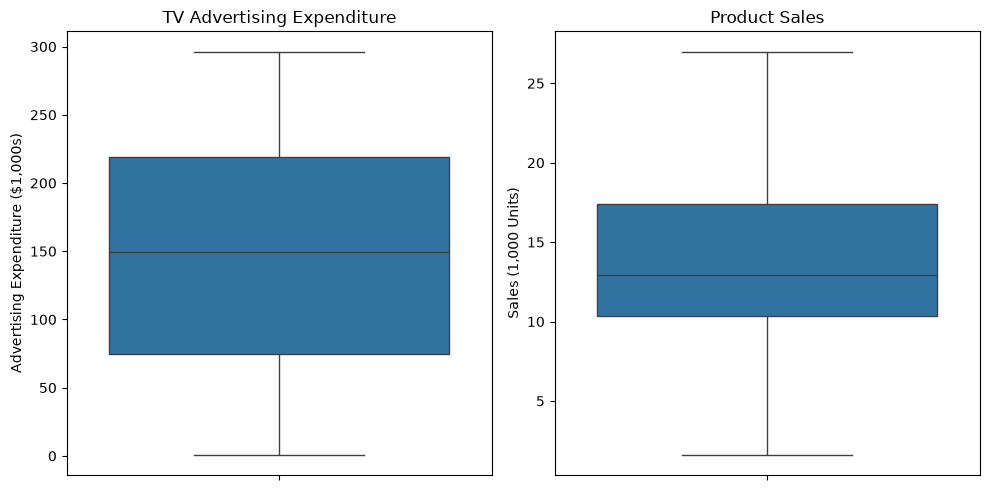

In [9]:
# Boxplots
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

sns.boxplot(y=df["TV"], ax=axes[0])
axes[0].set_title("TV Advertising Expenditure")
axes[0].set_ylabel("Advertising Expenditure ($1,000s)")

sns.boxplot(y=df["sales"], ax=axes[1])
axes[1].set_title("Product Sales")
axes[1].set_ylabel("Sales (1,000 Units)")

plt.tight_layout()
plt.show()

## EDA Results

The exploratory data analysis reveals a **strong positive relationship** between TV advertising expenditure and product sales.

The calculated **Pearson correlation coefficient is 0.7822**, indicating that higher TV advertising expenditure is generally associated with increased sales.

The scatterplot shows an approximately linear relationship, although sales appear more variable at higher advertising expenditure levels.

#### Boxplot Analysis

The boxplots provide additional insights into the distributions of both variables:

- **TV Advertising Expenditure:** The median expenditure is approximately $150,000, with values ranging from nearly $0 to $300,000.
- **Product Sales:** The median sales volume is approximately 13,000 units, with observations ranging from roughly 2,000 to 27,000 units.
- **Outliers:** Neither boxplot identifies any observations beyond the whiskers using the standard 1.5 × IQR rule.
- **Variability:** Both variables exhibit considerable variation across observations, with TV advertising expenditure covering a wide range of spending levels.

#### Overall Findings

The EDA findings suggest that **simple linear regression is an appropriate starting point** for examining the relationship between TV advertising expenditure and product sales.

The strong positive correlation and approximately linear trend support fitting a regression model, while the increasing variability in sales suggests that further diagnostic analysis may be necessary to evaluate the assumption of constant error variance.

## 3. Simple Linear Regression Model

A simple linear regression model is fitted to examine the relationship between **TV advertising expenditure** and **product sales**.

The model uses the following variables:

- **Independent Variable (X):** TV advertising expenditure ($1,000s).
- **Dependent Variable (y):** Product sales (1,000 units).

The model estimates how much predicted product sales change for each additional $1,000 spent on TV advertising.

In [7]:
# Define independent and dependent variables
X = df["TV"]
y = df["sales"]

# Fit simple linear regression
model = lm_manual(X, y)

OLS Summary:
------------------------------------------------------------------------------------------------------------
Response variable:   sales
Predictors:          1
Observations used:   200
Rows removed:        0
------------------------------------------------------------------------------------------------------------
Coefficient Estimates
Term                  Estimate    Std. Error     t value       P-value                        95% CI
------------------------------------------------------------------------------------------------------------
Intercept               7.0326        0.4578     15.3603     1.406e-35              (6.1297, 7.9355)
TV                      0.0475        0.0027     17.6676     1.467e-42              (0.0422, 0.0528)
------------------------------------------------------------------------------------------------------------
Residual standard error: 3.2587 on 198 degrees of freedom
R-squared: 0.6119, Adjusted R-squared: 0.6099
F-statistic: 312.1450 on

### 3. Regression Results

#### Estimated Regression Equation

The fitted simple linear regression equation is:

$$
\widehat{Sales} = 7.0326 + 0.0475(TV)
$$

For every additional $1,000 spent on TV advertising, predicted sales increase by approximately **47.5 units**.

#### Hypothesis Testing

We test whether TV advertising expenditure is a statistically significant predictor of sales.

$$
H_0: \beta_1 = 0
$$

$$
H_a: \beta_1 \neq 0
$$

**Significance Level:** $\alpha = 0.05$

**Results:**
- **t-statistic:** 17.6676
- **p-value:** 1.467e-42
- **R-squared:** 0.6119
- **95% CI for slope:** (0.0422, 0.0528)

#### Conclusion

Since the **p-value < 0.05**, we reject the null hypothesis. There is strong statistical evidence of a positive linear relationship between TV advertising expenditure and product sales.

The model explains approximately **61.19% of the variation in sales**, suggesting that TV advertising expenditure is a useful predictor of product sales.


## 4. Regression Line Visualization

The fitted regression line is plotted alongside the observed data to visually assess how well the model captures the relationship between **TV advertising expenditure** and **product sales**.

The visualization helps evaluate:

- **Model fit:** How closely the regression line follows the observed data.
- **Linear trend:** Whether predicted sales increase as advertising expenditure increases.
- **Prediction errors:** How far individual observations deviate from the fitted regression line.

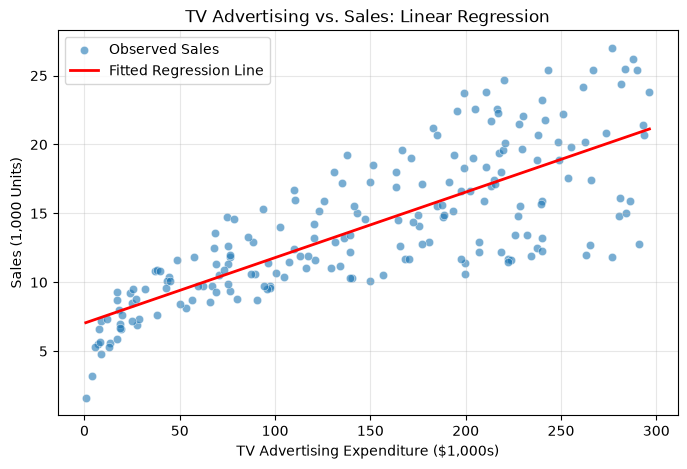

In [8]:
# Generate predictions using our regression model
x_line = np.linspace(X.min(), X.max(), 200)
y_line = model.predict(x_line)

# Plot observed data
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="TV", y="sales",
                alpha=0.6, label="Observed Sales")

# Plot fitted regression line
plt.plot(x_line, y_line, color="red",
         linewidth=2, label="Fitted Regression Line")

plt.title("TV Advertising vs. Sales: Linear Regression")
plt.xlabel("TV Advertising Expenditure ($1,000s)")
plt.ylabel("Sales (1,000 Units)")

plt.legend()
plt.grid(alpha=0.3)
plt.show()


#### Regression Line Interpretation

The fitted regression line shows a **positive linear relationship** between TV advertising expenditure and product sales.

- **Positive trend:** Predicted sales increase as TV advertising expenditure increases.
- **Model fit:** The regression line captures the overall upward trend, although several observations deviate from the fitted values.
- **Variability:** Sales appear more spread out at higher advertising expenditure levels, suggesting possible heteroscedasticity.

With an **R-squared of 0.6119**, the model explains approximately **61.19% of the variation in sales**.

Overall, the visualization suggests that TV advertising expenditure is a useful predictor of sales, although additional diagnostic analysis is needed to evaluate the model's assumptions.

## 5. Regression Diagnostics

Regression diagnostics are performed to evaluate the validity of the simple linear regression model and identify potential violations of its assumptions.

Four diagnostic plots are examined:

1. **Residuals vs. Fitted:** Evaluates linearity and checks for patterns or nonconstant error variance.
2. **Normal Q-Q Plot:** Assesses whether the residuals approximately follow a normal distribution.
3. **Scale-Location Plot:** Examines whether the variance of residuals remains approximately constant across fitted values.
4. **Residuals vs. Leverage:** Identifies potentially influential observations using leverage and Cook's distance.

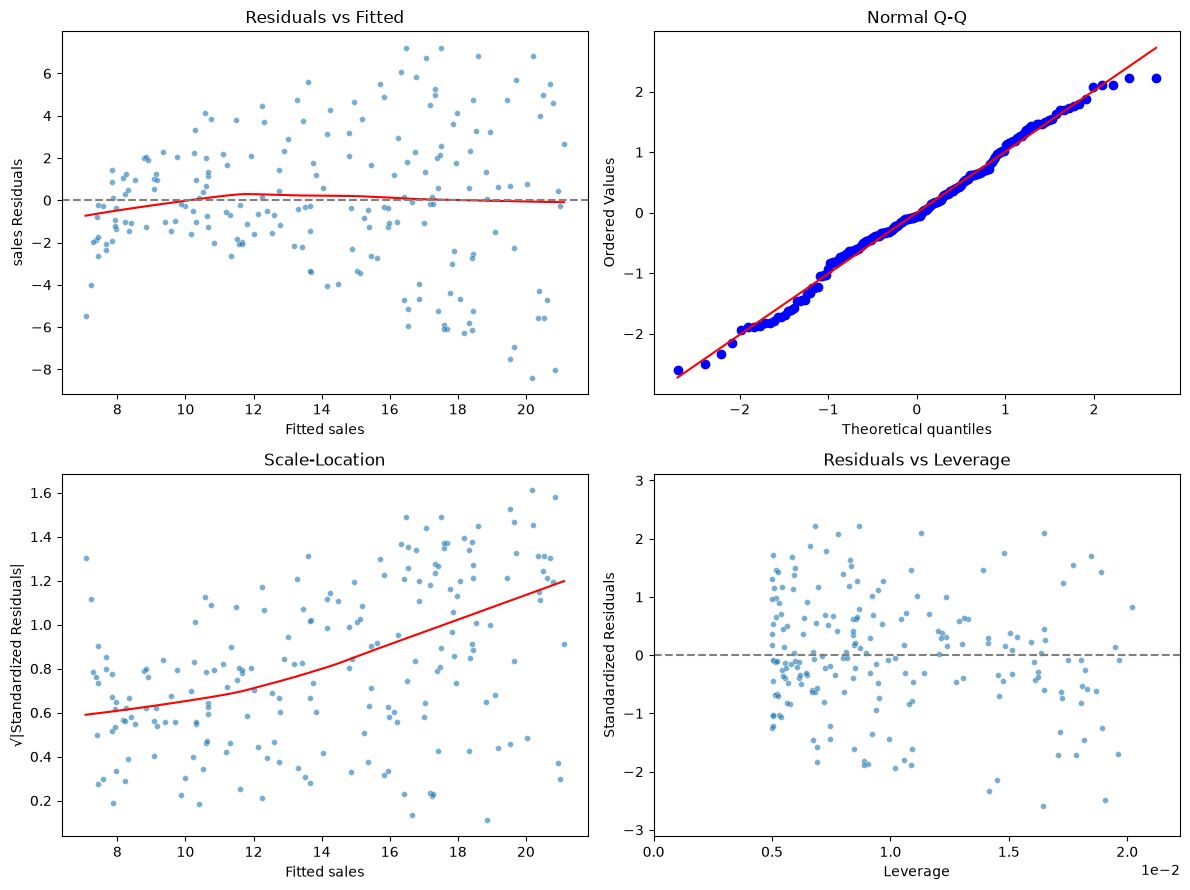

In [11]:
# Regression diagnostic plots
model.plot_diagnostics()

## 5. Regression Diagnostic Results

The diagnostic plots were examined to evaluate the assumptions of the simple linear regression model.

- **Residuals vs. Fitted:** Residuals are generally centered around zero, but their spread increases as fitted sales increase, suggesting nonconstant variance.
- **Normal Q-Q:** Residuals approximately follow a normal distribution, with minor deviations in the tails.
- **Scale-Location:** The increasing trend provides evidence of **heteroscedasticity**, indicating that residual variance is not constant.
- **Residuals vs. Leverage:** Several observations exhibit relatively large standardized residuals. Further examination of Cook's distance is needed to determine their influence.

#### Overall Assessment

The model captures the positive relationship between TV advertising expenditure and product sales. However, the diagnostic plots indicate a potential violation of the **constant variance assumption**.

Although the model explains approximately **61.19% of sales variation**, heteroscedasticity may affect the reliability of conventional statistical inference.

Further analysis using **heteroscedasticity-robust standard errors** or alternative modeling approaches may be appropriate.

### 6. Breusch-Pagan Test for Heteroscedasticity

The diagnostic plots suggest that residual variance increases as predicted sales increase. To formally investigate this, the **Breusch-Pagan test** is conducted.

#### Hypotheses

$$
H_0: \text{The error variance is constant (homoscedasticity)}
$$

$$
H_a: \text{The error variance is not constant (heteroscedasticity)}
$$

**Significance level:** $\alpha = 0.05$

- **p-value < 0.05:** Reject the null hypothesis, indicating evidence of heteroscedasticity.
- **p-value ≥ 0.05:** Fail to reject the null hypothesis; insufficient evidence of heteroscedasticity.

In [13]:
# Fit auxiliary regression using TV expenditure
aux_model = lm_manual(X, model.residuals ** 2)
# Calculate Breusch-Pagan LM statistic
n = model.n
LM = n * aux_model.R_squared
# Calculate p-value
p_value = chi2.sf(LM, df=1)
# Display results
print("Breusch-Pagan Test")
print("-------------------------")
print(f"LM Statistic: {LM:.4f}")
print(f"P-value: {p_value:.6g}")
if p_value < 0.05:
    print("Reject H0: Evidence of heteroscedasticity")
else:
    print("Fail to reject H0: Insufficient evidence of heteroscedasticity")



OLS Summary:
------------------------------------------------------------------------------------------------------------
Response variable:   y
Predictors:          1
Observations used:   200
Rows removed:        0
------------------------------------------------------------------------------------------------------------
Coefficient Estimates
Term                  Estimate    Std. Error     t value       P-value                        95% CI
------------------------------------------------------------------------------------------------------------
Intercept              -1.2865        1.7259     -0.7454        0.4569             (-4.6900, 2.1170)
TV                      0.0802        0.0101      7.9115     1.762e-13              (0.0602, 0.1002)
------------------------------------------------------------------------------------------------------------
Residual standard error: 12.2839 on 198 degrees of freedom
R-squared: 0.2402, Adjusted R-squared: 0.2364
F-statistic: 62.5914 on 1 a